# Day 61 - Pretrained Models, Object Detection 
- Understand pretrained models and transfer learning.
- Run image classification with a pretrained Keras model.
- Understand localization, bounding boxes, object detection, and YOLO.
- Explore semantic segmentation and pixel-level labels.

## 1. Check your environment

We will use TensorFlow/Keras, NumPy, Matplotlib, and Pillow.

If an import fails, install the missing package in the same Python environment that runs your Jupyter kernel. For example, from your Conda Prompt:

```bash
python -m pip install tensorflow matplotlib pillow
```

Avoid reinstalling packages if they are already working.

In [26]:
import sys
print("Python executable:", sys.executable)

import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)

try:
    import tensorflow as tf
    from tensorflow import keras
    print("TensorFlow version:", tf.__version__)
except ImportError as exc:
    print("TensorFlow import failed:", exc)
    print("Install TensorFlow in this notebook's active environment, then restart the kernel.")

Python executable: c:\Users\Puneeth\anaconda3\envs\tf_env\python.exe
NumPy version: 2.4.6
TensorFlow version: 2.21.0


## 2. What is a pretrained model?

A **pretrained model** has already learned useful patterns from a large dataset. For example, a convolutional neural network may learn edges and textures in early layers and more complex visual patterns in deeper layers.

**Transfer learning** reuses that learned knowledge for a new task.

Typical workflow:
1. Load a pretrained model.
2. Replace or remove its original classification head if needed.
3. Freeze the learned base and train a new head for your classes.
4. Optionally unfreeze some base layers and fine-tune carefully.

### Feature extraction vs. fine-tuning

| Approach | What changes? | Useful when |
|---|---|---|
| Feature extraction | Train a new head; keep the base frozen | Starting point, small datasets |
| Fine-tuning | Unfreeze some pretrained layers and train with a low learning rate | The new task needs further adaptation |

## 3. Load a pretrained MobileNetV2 model

MobileNetV2 is a relatively lightweight image-classification model. Here we use its ImageNet-trained weights and original 1,000-class output layer.

`include_top=True` keeps the original classification head. For transfer learning to your own classes, we usually use `include_top=False`.

In [27]:
# This cell downloads pretrained weights if they are not cached.
import tensorflow as tf
from tensorflow import keras

model = keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=True
)

print("Model loaded.")
print("Number of parameters:", model.count_params())

Model loaded.
Number of parameters: 3538984


## 4. Classify an image

Set `IMAGE_PATH` to a local image file, such as a photo of a dog, cat, bicycle, or flower. The image is resized to 224 × 224 pixels, preprocessed as MobileNetV2 expects, and passed to the model.

If you do not have an image handy, you can leave the path unchanged and run the cell to see the instructions.

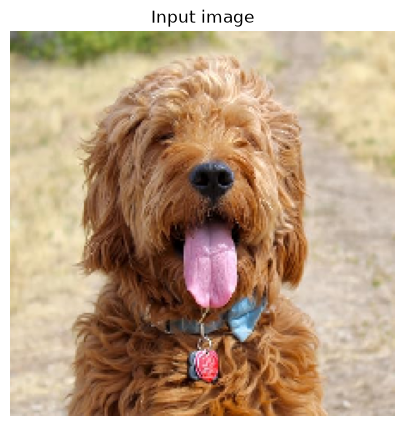

Top 3 predictions:
otterhound                10.68%
Irish_terrier             10.31%
Tibetan_terrier           9.03%


In [28]:
from pathlib import Path
from tensorflow.keras.utils import load_img, img_to_array

IMAGE_PATH = "dog_sample.jpg"  # <-- Change this to your image path

if not Path(IMAGE_PATH).exists():
    print(f"Image not found: {IMAGE_PATH}")
    print("Update IMAGE_PATH to point to an existing .jpg, .jpeg, or .png file.")
else:
    image = load_img(IMAGE_PATH, target_size=(224, 224))
    image_array = img_to_array(image)
    batch = np.expand_dims(image_array, axis=0)

    # MobileNetV2 preprocessing scales pixel values to [-1, 1].
    batch = keras.applications.mobilenet_v2.preprocess_input(batch)

    probabilities = model.predict(batch, verbose=0)
    top_predictions = keras.applications.mobilenet_v2.decode_predictions(
        probabilities, top=3
    )[0]

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title("Input image")
    plt.show()

    print("Top 3 predictions:")
    for _, label, score in top_predictions:
        print(f"{label:25s} {score:.2%}")

## 5. Transfer learning: build a new classification head

This example creates a MobileNetV2 feature extractor for a **two-class** problem. It does not train because a labeled dataset is not supplied. The code shows the model structure you would use once you have training and validation folders.

Expected folder structure:

```text
my_dataset/
    train/
        cats/
        dogs/
    validation/
        cats/
        dogs/
```

The code uses `include_top=False`, freezes the base, and adds a small classification head.

In [29]:
base_model = keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False  # Freeze pretrained features

inputs = keras.Input(shape=(224, 224, 3))
x = keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.2)(x)
outputs = keras.layers.Dense(2, activation="softmax")(x)

transfer_model = keras.Model(inputs, outputs)
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

transfer_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_3 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_3 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Classification, localization, and object detection

These tasks answer different questions:

- **Classification:** What is in the image?
- **Localization:** What is the main object, and where is it?
- **Object detection:** Which objects are present, and where is each one?

A common bounding-box format is `(x_min, y_min, x_max, y_max)`, measured in image pixels.

In [30]:
# A simple bounding-box example (no machine-learning model needed).
box = (50, 30, 200, 180)
x_min, y_min, x_max, y_max = box

print("Box:", box)
print("Width:", x_max - x_min)
print("Height:", y_max - y_min)

Box: (50, 30, 200, 180)
Width: 150
Height: 150


### Draw example bounding boxes

The picture below is a synthetic illustration. The rectangles are manually defined, not predictions from an object detector.

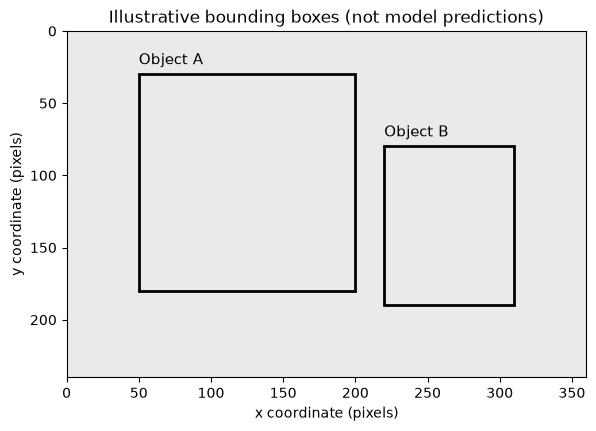

In [31]:
from matplotlib.patches import Rectangle

# Synthetic canvas
canvas = np.ones((240, 360, 3), dtype=float) * 0.92
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.imshow(canvas)
ax.add_patch(Rectangle((50, 30), 150, 150, fill=False, linewidth=2))
ax.add_patch(Rectangle((220, 80), 90, 110, fill=False, linewidth=2))
ax.text(50, 23, "Object A", fontsize=11)
ax.text(220, 73, "Object B", fontsize=11)
ax.set_title("Illustrative bounding boxes (not model predictions)")
ax.set_xlim(0, 360)
ax.set_ylim(240, 0)
ax.set_xlabel("x coordinate (pixels)")
ax.set_ylabel("y coordinate (pixels)")
plt.show()

## 7. Object detection and YOLO

**YOLO** means *You Only Look Once*. YOLO is a family of single-stage object detectors that predicts object locations and classes efficiently.

A detector commonly outputs:
- bounding-box coordinates,
- class scores or labels,
- confidence scores.

**Non-maximum suppression (NMS)** is a post-processing method that helps remove duplicate, highly overlapping boxes for the same class.

A common comparison:
- **Faster R-CNN:** two-stage detector; proposes regions, then classifies/refines them.
- **YOLO:** single-stage detector; predicts detections more directly.

Neither is always best: accuracy, speed, data, model version, and deployment environment all matter.

## 8. Fully convolutional networks (FCNs)

A fully convolutional network can produce a spatial output map rather than only one image-level class prediction. FCNs are used for dense prediction tasks such as semantic segmentation.

A segmentation model often:
1. extracts features,
2. builds lower-resolution feature maps,
3. upsamples or decodes them,
4. predicts a class for each pixel.

Related encoder-decoder architectures include U-Net, which uses skip connections to help preserve spatial detail.

## 9. Semantic segmentation: a tiny example

Semantic segmentation assigns a class ID to each pixel. In this toy map:
- `0` = background
- `1` = road
- `2` = car

This is a hand-created class map for learning; it is not produced by a neural network.

Shape: (5, 6)
[[0 0 0 0 0 0]
 [0 0 1 1 0 0]
 [1 1 1 1 1 1]
 [1 1 2 2 1 1]
 [1 1 2 2 1 1]]


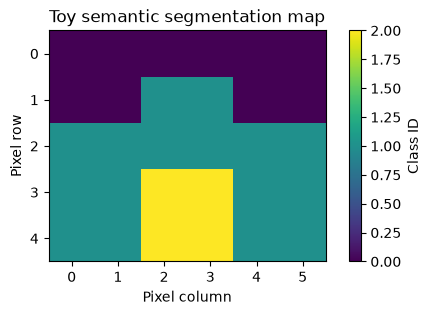

In [32]:
segmentation_map = np.array([
    [0, 0, 0, 0, 0, 0],
    [0, 0, 1, 1, 0, 0],
    [1, 1, 1, 1, 1, 1],
    [1, 1, 2, 2, 1, 1],
    [1, 1, 2, 2, 1, 1],
])

print("Shape:", segmentation_map.shape)
print(segmentation_map)

plt.figure(figsize=(6, 3))
plt.imshow(segmentation_map, interpolation="nearest")
plt.title("Toy semantic segmentation map")
plt.xlabel("Pixel column")
plt.ylabel("Pixel row")
plt.colorbar(label="Class ID")
plt.show()

### Semantic vs. instance segmentation

- **Semantic segmentation:** every pixel receives a category; two cars can share the same `car` label.
- **Instance segmentation:** separate masks are predicted for individual objects, so car 1 and car 2 can be distinguished.

### Quick question
If two people are standing next to each other, which task is designed to produce a separate mask for each person?

Write your answer in the cell below.

In [33]:
# Your answer:
answer = ""

# Edit this string, then run the cell.
print(answer)

## 10. Summary table

| Concept | Main output | Example use |
|---|---|---|
| Pretrained model | Learned weights from an earlier training task | Reuse ImageNet features |
| Transfer learning | A model adapted to a new task | Cat vs. dog classification |
| Classification | Image-level label(s) | Identify a fruit |
| Localization | Class + one object's position | Locate the main face |
| Object detection | Multiple boxes + labels | Detect cars and pedestrians |
| FCN | Spatial prediction map | Dense visual prediction |
| Semantic segmentation | Class ID for each pixel | Label road, sky, and buildings |
| Instance segmentation | Separate object masks | Distinguish individual people |
